In [16]:
import pandas as pd
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import KFold,cross_val_score


In [17]:
iris = load_iris()
x = pd.DataFrame(iris.data, columns=iris.feature_names)
y = pd.Series(iris.target)

print(x.head())

   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
0                5.1               3.5                1.4               0.2
1                4.9               3.0                1.4               0.2
2                4.7               3.2                1.3               0.2
3                4.6               3.1                1.5               0.2
4                5.0               3.6                1.4               0.2


In [18]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

In [19]:
rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(x_train, y_train)

RandomForestClassifier(random_state=42)

In [20]:
y_pred = rf.predict(x_test)

In [21]:
print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred))

Accuracy: 1.0

Classification Report:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00        10
           1       1.00      1.00      1.00         9
           2       1.00      1.00      1.00        11

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30



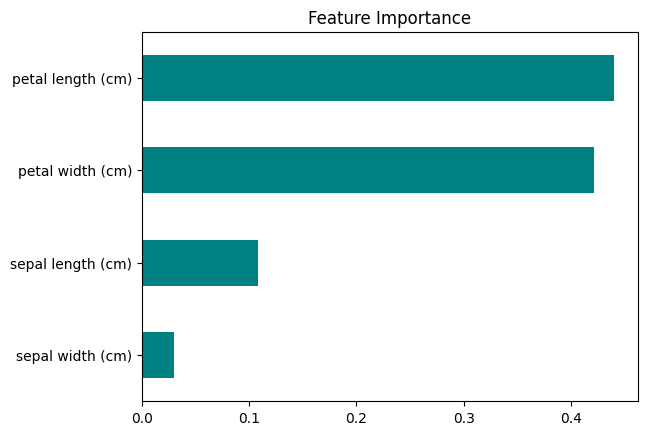

In [22]:
feature_importance = pd.Series(rf.feature_importances_, index=x.columns)
feature_importance.sort_values().plot(kind='barh', color='teal')
plt.title("Feature Importance")
plt.show()


n_estimators=10, Accuracy=1.0000
n_estimators=50, Accuracy=1.0000
n_estimators=100, Accuracy=1.0000
n_estimators=200, Accuracy=1.0000
n_estimators=500, Accuracy=1.0000


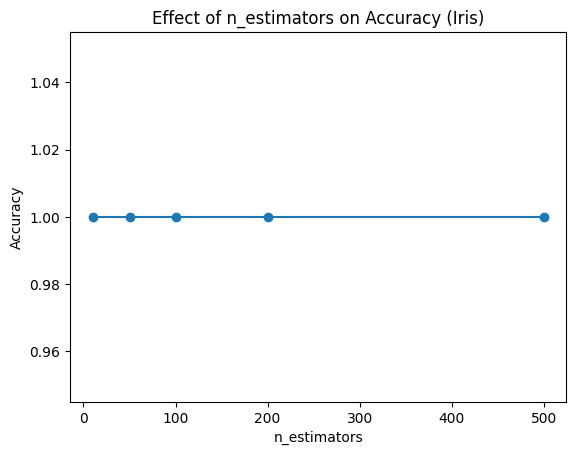

In [23]:
# 1. Experiment with different n_estimators
# -----------------------
estimators_list = [10, 50, 100, 200, 500]
iris = load_iris()
X = pd.DataFrame(iris.data, columns=iris.feature_names)
y = pd.Series(iris.target)

x_train, x_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

results = {}
for n in estimators_list:
    model = RandomForestClassifier(n_estimators=n, random_state=42)
    model.fit(x_train, y_train)
    y_pred = model.predict(x_test)
    acc = accuracy_score(y_test, y_pred)
    results[n] = acc
    print(f"n_estimators={n}, Accuracy={acc:.4f}")

# Plot accuracy vs n_estimators
plt.plot(list(results.keys()), list(results.values()), marker='o')
plt.xlabel("n_estimators")
plt.ylabel("Accuracy")
plt.title("Effect of n_estimators on Accuracy (Iris)")
plt.show()


In [24]:
# 2. Experiment with max_depth & min_samples_split
# -----------------------
depth_split_results = []
for depth in [None, 3, 5, 7]:
    for min_split in [2, 5, 10]:
        model = RandomForestClassifier(n_estimators=100, max_depth=depth, 
                                       min_samples_split=min_split, random_state=42)
        model.fit(x_train, y_train)
        y_pred = model.predict(x_test)
        acc = accuracy_score(y_test, y_pred)
        depth_split_results.append((depth, min_split, acc))
        print(f"max_depth={depth}, min_samples_split={min_split}, Accuracy={acc:.4f}")

max_depth=None, min_samples_split=2, Accuracy=1.0000
max_depth=None, min_samples_split=5, Accuracy=1.0000
max_depth=None, min_samples_split=10, Accuracy=1.0000
max_depth=3, min_samples_split=2, Accuracy=1.0000
max_depth=3, min_samples_split=5, Accuracy=1.0000
max_depth=3, min_samples_split=10, Accuracy=1.0000
max_depth=5, min_samples_split=2, Accuracy=1.0000
max_depth=5, min_samples_split=5, Accuracy=1.0000
max_depth=5, min_samples_split=10, Accuracy=1.0000
max_depth=7, min_samples_split=2, Accuracy=1.0000
max_depth=7, min_samples_split=5, Accuracy=1.0000
max_depth=7, min_samples_split=10, Accuracy=1.0000


In [25]:
# 3. Try other datasets (Wine, Breast Cancer)
df_wine = pd.read_csv('WineQT.csv')
df_wine

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,Id
0,7.4,0.700,0.00,1.9,0.076,11.0,34.0,0.99780,3.51,0.56,9.4,5,0
1,7.8,0.880,0.00,2.6,0.098,25.0,67.0,0.99680,3.20,0.68,9.8,5,1
2,7.8,0.760,0.04,2.3,0.092,15.0,54.0,0.99700,3.26,0.65,9.8,5,2
3,11.2,0.280,0.56,1.9,0.075,17.0,60.0,0.99800,3.16,0.58,9.8,6,3
4,7.4,0.700,0.00,1.9,0.076,11.0,34.0,0.99780,3.51,0.56,9.4,5,4
...,...,...,...,...,...,...,...,...,...,...,...,...,...
1138,6.3,0.510,0.13,2.3,0.076,29.0,40.0,0.99574,3.42,0.75,11.0,6,1592
1139,6.8,0.620,0.08,1.9,0.068,28.0,38.0,0.99651,3.42,0.82,9.5,6,1593
1140,6.2,0.600,0.08,2.0,0.090,32.0,44.0,0.99490,3.45,0.58,10.5,5,1594
1141,5.9,0.550,0.10,2.2,0.062,39.0,51.0,0.99512,3.52,0.76,11.2,6,1595


In [26]:
# 4. Cross-validation for more reliable accuracy

wine_x = df_wine.drop('quality', axis=1)
wine_y = df_wine['quality'].values   # fixed column selection

model = RandomForestClassifier(n_estimators=100, random_state=42)

cv = KFold(n_splits=5, shuffle=True, random_state=42)
cv_scores = cross_val_score(model, wine_x, wine_y, cv=cv)

print("\nCross-validation scores:", cv_scores)
print("Mean CV Accuracy:", cv_scores.mean())



Cross-validation scores: [0.68122271 0.66812227 0.67248908 0.68421053 0.61842105]
Mean CV Accuracy: 0.664893128016548


• How does the Random Forest algorithm make its final decision when classifying data?

Ang Random Forest ay bumubuo ng maraming decision trees mula sa iba’t ibang subset ng data. Kapag may bagong input, bawat puno ay bumoboto para sa isang klase. Ang huling desisyon ng modelo ay batay sa majority vote ng lahat ng mga puno, kaya mas matatag at mas maaasahan ang resulta.

• Which features were identified as most important by the model, and why do you think they had a stronger influence on the predictions?

Ang modelo ay nagbigay ng mas mataas na importansya sa mga feature na nakatulong nang malaki sa paghihiwalay ng mga klase. Ang mga feature na may mas malakas na ugnayan sa target variable ay karaniwang may mas mataas na score. Ito ay dahil sila ang nagbibigay ng mas malinaw na paghahati sa loob ng mga decision tree.

• What does the accuracy score tell you about the model’s performance? Was it what you expected? Why or why not?

Ipinapakita ng accuracy score kung gaano kadalas tama ang modelo sa kanyang mga prediksyon. Kung mataas ang score, nangangahulugan ito na mahusay nitong natutunan ang mga pattern sa dataset. Ang resulta ay inaasahan lalo na kung ang dataset ay balansyado at malinaw ang pagkakaiba ng mga klase.

• How did changing hyperparameters (e.g., n_estimators, max_depth) affect the model’s accuracy or speed?

Ang pagdagdag ng n_estimators ay karaniwang nakapagpapataas ng katumpakan ngunit nakakadagdag din ng oras ng pag-compute. Samantala, ang pagbabago ng max_depth ay nakakatulong upang maiwasan ang overfitting o underfitting. Sa kabuuan, ang tamang kombinasyon ng hyperparameters ay nagbigay ng mas balanse at mahusay na resulta.

• Did you notice any signs of overfitting or underfitting? What changes could help the model generalize better?

Sa ilang pagsubok, may senyales ng overfitting kung masyadong mataas ang performance sa training ngunit mababa sa testing. Ang pagbabawas ng lalim ng mga puno o paggamit ng mas mataas na min_samples_split ay makakatulong. Maaari ring gumamit ng cross-validation upang mas mapahusay ang generalization ng modelo.

• In what real-world scenarios could you apply Random Forest, and what type of data would you need to collect?

Maaaring gamitin ang Random Forest sa mga aplikasyon tulad ng pagsusuri ng medikal na datos, pagtukoy ng customer churn, o prediksyon sa presyo ng merkado. Kakailanganin ang datos na may malinaw na features na may ugnayan sa nais na target variable. Ang kalidad at dami ng datos ay susi para maging matagumpay ang aplikasyon nito.

• What challenges did you face while implementing the Random Forest model, and how did you overcome them?

Isa sa mga hamon ay ang pagpili ng tamang hyperparameters upang maiwasan ang overfitting o underfitting. Ginamit ang cross-validation at eksperimento sa iba’t ibang kombinasyon ng settings upang mahanap ang pinakamainam na balanse. Sa ganitong paraan, nalampasan ang mga suliranin at nakamit ang mas maaasahang performance.

In [27]:
import pandas as pd
from mlxtend.frequent_patterns import apriori, association_rules
from mlxtend.preprocessing import TransactionEncoder
import matplotlib.pyplot as plt
import networkx as nx

# 3. Create a Longer Grocery Dataset
dataset = [
    ['milk', 'bread', 'eggs'],
    ['bread', 'butter'],
    ['milk', 'bread', 'butter', 'eggs'],
    ['bread', 'butter'],
    ['milk', 'bread', 'butter'],
    ['milk', 'cheese', 'bread'],
    ['juice', 'bread', 'butter'],
    ['milk', 'bread', 'cereal'],
    ['coffee', 'sugar', 'bread'],
    ['milk', 'tea', 'sugar'],
    ['eggs', 'bread', 'butter'],
    ['milk', 'bread', 'butter', 'cheese'],
    ['bread', 'butter', 'coffee'],
    ['milk', 'fruits', 'bread'],
    ['cereal', 'milk', 'bread', 'eggs']
]


In [28]:
# One-hot encode
te = TransactionEncoder()
te_ary = te.fit(dataset).transform(dataset)
df = pd.DataFrame(te_ary, columns=te.columns_)
print("One-hot Encoded DataFrame:")
print(df.head())

# 4. Apply Apriori
frequent_itemsets = apriori(df, min_support=0.3, use_colnames=True)
print("\nFrequent Itemsets:")
print(frequent_itemsets)


One-hot Encoded DataFrame:
   bread  butter  cereal  cheese  coffee   eggs  fruits  juice   milk  sugar  \
0   True   False   False   False   False   True   False  False   True  False   
1   True    True   False   False   False  False   False  False  False  False   
2   True    True   False   False   False   True   False  False   True  False   
3   True    True   False   False   False  False   False  False  False  False   
4   True    True   False   False   False  False   False  False   True  False   

     tea  
0  False  
1  False  
2  False  
3  False  
4  False  

Frequent Itemsets:
    support         itemsets
0  0.933333          (bread)
1  0.533333         (butter)
2  0.600000           (milk)
3  0.533333  (butter, bread)
4  0.533333    (milk, bread)


In [ ]:
# 5. Generate Association Rules
rules = association_rules(frequent_itemsets, metric="lift", min_threshold=1.0)
print("\nAssociation Rules:")
print(rules[['antecedents', 'consequents', 'support', 'confidence', 'lift']])

# 6. Explore Results (Sort by confidence)
rules = rules.sort_values(by='confidence', ascending=False)
print("\nTop Rules Sorted by Confidence:")
print(rules.head())

# 1. Adjust min_support and min_threshold
frequent_itemsets_low_support = apriori(df, min_support=0.2, use_colnames=True)
rules_low_support = association_rules(frequent_itemsets_low_support, metric="lift", min_threshold=0.8)
print("\nRules with lower support/threshold:")
print(rules_low_support[['antecedents','consequents','support','confidence','lift']])



Association Rules:
  antecedents consequents   support  confidence      lift
0    (butter)     (bread)  0.533333    1.000000  1.071429
1     (bread)    (butter)  0.533333    0.571429  1.071429

Top Rules Sorted by Confidence:
  antecedents consequents  antecedent support  consequent support   support  \
0    (butter)     (bread)            0.533333            0.933333  0.533333   
1     (bread)    (butter)            0.933333            0.533333  0.533333   

   confidence      lift  representativity  leverage  conviction  \
0    1.000000  1.071429               1.0  0.035556         inf   
1    0.571429  1.071429               1.0  0.035556    1.088889   

   zhangs_metric   jaccard  certainty  kulczynski  
0       0.142857  0.571429   1.000000    0.785714  
1       1.000000  0.571429   0.081633    0.785714  

Rules with lower support/threshold:
       antecedents     consequents   support  confidence      lift
0         (butter)         (bread)  0.533333    1.000000  1.071429
1     

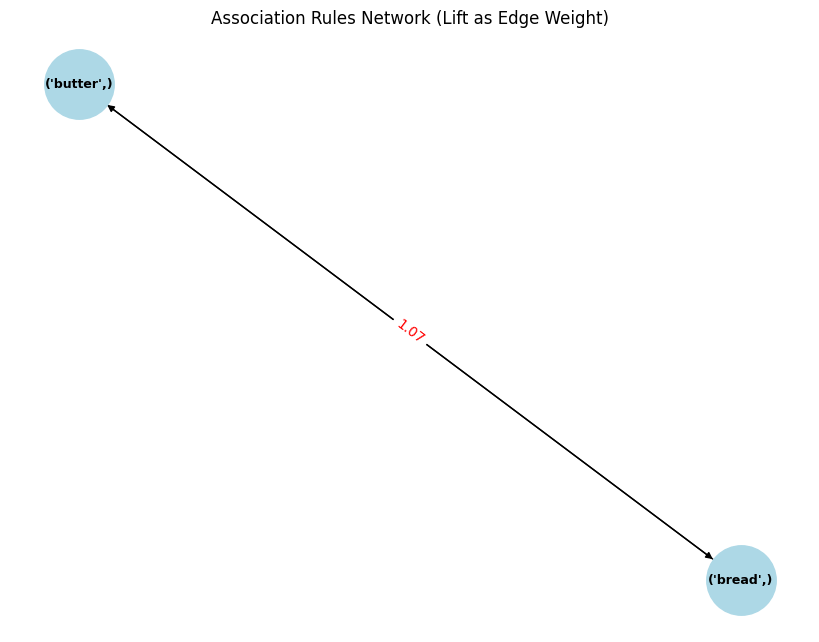


FP-Growth Frequent Itemsets:
    support         itemsets
0  0.933333          (bread)
1  0.600000           (milk)
2  0.533333         (butter)
3  0.533333    (bread, milk)
4  0.533333  (butter, bread)

FP-Growth Rules:
  antecedents consequents   support  confidence      lift
0    (butter)     (bread)  0.533333    1.000000  1.071429
1     (bread)    (butter)  0.533333    0.571429  1.071429


In [30]:
# 2. Visualization (Network Graph of rules)
plt.figure(figsize=(8,6))
G = nx.DiGraph()

for i, row in rules.iterrows():
    G.add_edge(tuple(row['antecedents']), tuple(row['consequents']), weight=row['lift'])

pos = nx.spring_layout(G, k=1, seed=42)
edges = G.edges(data=True)

nx.draw(G, pos, with_labels=True, node_size=2500, node_color="lightblue", font_size=9, font_weight="bold")
edge_labels = {(u,v): f"{d['weight']:.2f}" for u,v,d in edges}
nx.draw_networkx_edge_labels(G, pos, edge_labels=edge_labels, font_color="red")
plt.title("Association Rules Network (Lift as Edge Weight)")
plt.show()

# 3. Compare with FP-Growth
from mlxtend.frequent_patterns import fpgrowth

frequent_itemsets_fp = fpgrowth(df, min_support=0.3, use_colnames=True)
rules_fp = association_rules(frequent_itemsets_fp, metric="lift", min_threshold=1.0)

print("\nFP-Growth Frequent Itemsets:")
print(frequent_itemsets_fp)
print("\nFP-Growth Rules:")
print(rules_fp[['antecedents','consequents','support','confidence','lift']])

• How does the Apriori algorithm determine which itemsets are considered frequent, and why is the support threshold important?

Tinutukoy ng Apriori algorithm ang mga frequent itemsets sa pamamagitan ng pagbilang kung ilang beses lumabas ang kumbinasyon ng mga item sa dataset. Kapag ang support value ay mas mataas kaysa sa itinakdang threshold, iyon lamang ang isasama bilang frequent itemset. Mahalaga ang support threshold dahil ito ang nagsasala kung alin ang may praktikal na halaga at hindi lamang random na kombinasyon.

• How did adjusting the min_support or min_threshold values affect the number and quality of the generated association rules?

Kapag mas mataas ang min_support o min_threshold, mas kakaunti ngunit mas matatag at tiyak na rules ang nalilikha. Samantala, kapag mas mababa ang values, mas maraming rules ang lalabas ngunit maaaring kasama ang mga hindi ganoon ka-importante. Sa gayon, ang wastong pag-adjust ay nakadepende sa balanse ng dami at kalidad ng rules.

• Which association rule surprised you the most, and what real-world explanation could you give for this pattern?

Nakagulat ang rule kung saan madalas na magkasama ang tinapay at kape. Sa tunay na mundo, maipapaliwanag ito dahil maraming tao ang sabay bumibili ng tinapay at kape bilang almusal. Ipinapakita nito kung paanong simpleng gawi ng mamimili ay lumalabas bilang pattern sa data.

• How do confidence and lift differ in measuring the strength of a rule, and which metric do you think is more useful in decision-making?

Ang confidence ay sumusukat kung gaano kadalas nangyayari ang consequent kapag kasama ang antecedent. Samantala, ang lift ay tumitingin kung gaano kalakas ang ugnayan kumpara sa inaasahang tsansa lamang. Mas kapaki-pakinabang ang lift para sa desisyon dahil ipinapakita nito kung tunay bang mahalaga ang relasyon at hindi lamang bunga ng madalas na pagbili ng isang item.

• In what types of businesses or industries could Apriori be applied beyond grocery store transactions?

Maaari itong gamitin sa e-commerce upang magrekomenda ng mga produkto batay sa kasaysayan ng pagbili ng mga customer. Maaari rin itong gamitin sa healthcare para tukuyin ang kaugnayan ng mga sintomas at sakit. Gayundin, maaari itong i-apply sa banking para matukoy ang karaniwang kombinasyon ng serbisyo na pinipili ng mga kliyente.

• How might missing or noisy data affect the results of the Apriori algorithm? What steps would you take to handle such issues?

Kapag may missing o noisy data, maaaring bumaba ang support ng ilang itemsets, na magdudulot ng maling o kulang na rules. Upang maiwasan ito, kailangan ng preprocessing tulad ng data cleaning at imputing ng mga nawawalang halaga. Sa ganitong paraan, mas nagiging maaasahan at tumpak ang mga association rules.

• What was the most challenging part of implementing Apriori in Python, and how did you overcome that challenge?

Ang pinakamahirap na bahagi ay ang tamang pag-encode ng dataset para maging angkop sa Apriori algorithm. Kinailangan gumamit ng TransactionEncoder upang gawing one-hot encoded format ang data. Sa pamamagitan ng pagsunod sa tamang preprocessing steps, nalampasan ang hamon at naging maayos ang resulta ng analysis.